# Question C: Does a clearly written abstract get cited more?

The brief asks whether abstract readability is associated with citations in *Financial Services
Review* (FSR). The practical interest is narrow and specific: an abstract is one of the few parts
of a submission an editor can ask an author to revise before publication, so the question is worth
answering only if an association is both large enough to act on and specific enough to FSR to
justify making the request.

The published evidence points both ways. Gazni (2011) and Didegah and Thelwall (2013) report that
more readable abstracts attract more citations, while Sienkiewicz and Altmann (2016) find the
opposite. The direction appears to depend on the field, which is why FSR has to be tested on its
own terms rather than assumed to follow a general pattern.

This notebook answers the question in two stages. Part 2 asks whether readability is associated
with citations at all. Part 3 asks whether that association holds *within FSR*, or whether it is
carried by the two comparator journals. The distinction turns out to matter more than the headline
result does.

**Data.** Scopus metadata for FSR and its two closest comparators, *Journal of Financial
Counseling and Planning* (JFCP) and *Financial Planning Review* (FPR).

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import textstat
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.figsize": (7.5, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e6e5e2",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#c9c8c4",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.labelcolor": GREY,
    "text.color": "#0b0b0b",
    "xtick.color": GREY,
    "ytick.color": GREY,
    "font.size": 9,
    "lines.linewidth": 2,
})

EXTRACTION_YEAR = 2026
JOURNAL_MAP = {
    "financial services review": "FSR",
    "financial planning review": "FPR",
    "journal of financial counseling and planning": "JFCP",
}
ORDER = ["FSR", "JFCP", "FPR"]

DATA_DIR = Path("../data")
FIG_DIR = Path("output")
FIG_DIR.mkdir(exist_ok=True)


# Part 1: Measuring abstract readability

## 1.1 Which index, and why three of them

Readability formulas score text on sentence length and word difficulty. The Gunning Fog Index is
the primary measure here, both because the brief names it and because it is the measure used in
the studies this question is testing against:

$$\text{Fog} = 0.4\left(\frac{\text{words}}{\text{sentences}} + 100\,\frac{\text{complex words}}{\text{words}}\right)$$

where a complex word has three or more syllables. The score approximates the years of formal
education a reader needs to follow the text on one reading.

Two alternatives are reported alongside it. Flesch Reading Ease and Flesch-Kincaid Grade Level use
the same two ingredients but weight them differently, measuring word difficulty as syllables per
word rather than counting words past a syllable threshold:

$$\text{FRE} = 206.835 - 1.015\,\frac{\text{words}}{\text{sentences}} - 84.6\,\frac{\text{syllables}}{\text{words}}$$

$$\text{FKG} = 0.39\,\frac{\text{words}}{\text{sentences}} + 11.8\,\frac{\text{syllables}}{\text{words}} - 15.59$$

Reporting all three guards against a finding that depends on one formula's particular weighting.
Flesch Reading Ease runs in the opposite direction to the other two, from easy to hard rather than
hard to easy, so a genuine association should show up as a *sign reversal* across the measures
rather than as agreement. That makes it a useful check: three measures agreeing in sign where one
of them is inverted is harder to produce by accident.

## 1.2 Data preparation

Two cleaning decisions affect the scores.

Abstracts in this export frequently end with a copyright statement, for example
`© 2020 Academy of Financial Services. All rights reserved.` This is boilerplate appended by the
publisher rather than author prose, and the journals differ in whether and how they append it. Left
in, it adds a short sentence of common words to some abstracts and not others, which shifts the
words-per-sentence term for reasons that have nothing to do with how the author wrote. Everything
from the first copyright marker onwards is therefore removed before scoring.

The analysis sample is the set of articles with a usable abstract and an author list. Seven records
carry the placeholder `[No abstract available]` and so have no text to score, and two have no
author identifier, which is needed for the team-size control.

In [2]:
COPYRIGHT = re.compile(r"©.*$|\bcopyright\b.*$", flags=re.IGNORECASE | re.DOTALL)

def strip_boilerplate(text):
    return COPYRIGHT.sub("", text).strip() if isinstance(text, str) else ""

master = pd.read_csv(DATA_DIR / "master_dataset.csv")
master["journal"] = master["source_title"].str.strip().str.lower().map(JOURNAL_MAP)
master["abstract_clean"] = master["abstract"].apply(strip_boilerplate)

# Drop missing or placeholder abstracts and missing author IDs
usable = (
    master["abstract"].notna()
    & (master["abstract"].str.strip() != "[No abstract available]")
    & master["authors_id"].notna()
)
d = master[usable].copy()

print(f"Analysis sample: {len(d):,} articles (dropped {(~usable).sum()})")
d["journal"].value_counts().reindex(ORDER)


Analysis sample: 1,353 articles (dropped 9)


journal
FSR     622
JFCP    622
FPR     109
Name: count, dtype: int64

### 1.3 Scoring

Scores come from the `textstat` package. Three covariates are built at the same time, each of which
is used later: abstract length in words, team size from the author identifier list, and
log-transformed paper age.

Age enters as $\log(2026 - \text{year} + 1)$. This is the same form Question A uses. It counts
years from publication to the end of the extraction year, and the $+1$ keeps the logarithm defined
for articles published in 2026.

In [3]:
d["fog"] = d["abstract_clean"].apply(textstat.gunning_fog)
d["fre"] = d["abstract_clean"].apply(textstat.flesch_reading_ease)
d["fkg"] = d["abstract_clean"].apply(textstat.flesch_kincaid_grade)

d["abstract_words"] = d["abstract_clean"].str.split().str.len()
d["n_authors"] = d["authors_id"].str.split(";").apply(len)
d["log_age"] = np.log(EXTRACTION_YEAR - d["year"] + 1)

d["is_FSR"] = (d["journal"] == "FSR").astype(int)
d["is_JFCP"] = (d["journal"] == "JFCP").astype(int)
d["is_FPR"] = (d["journal"] == "FPR").astype(int)

d[["fog", "fre", "fkg", "abstract_words", "n_authors", "cited_by"]].describe().round(2)


,fog,fre,fkg,abstract_words,n_authors,cited_by
count,"1,353.000","1,353.000","1,353.000","1,353.000","1,353.000","1,353.000"
mean,20.240,18.120,16.450,119.750,2.460,19.090
std,3.400,15.170,2.850,36.980,1.210,45.180
min,8.820,-28.740,7.970,26.000,1.000,0.000
25%,17.900,8.170,14.550,97.000,2.000,2.000
50%,20.140,18.220,16.340,110.000,2.000,6.000
75%,22.520,28.770,18.310,138.000,3.000,17.000
max,33.670,65.830,27.570,444.000,13.000,678.000


### 1.4 How readable are these abstracts?

In [4]:
desc = (
    d.groupby("journal")
    .agg(
        n=("fog", "size"),
        fog_mean=("fog", "mean"),
        fog_sd=("fog", "std"),
        fre_mean=("fre", "mean"),
        fkg_mean=("fkg", "mean"),
        words=("abstract_words", "mean"),
    )
    .reindex(ORDER)
    .round(1)
)

H, p = stats.kruskal(*[g["fog"].values for _, g in d.groupby("journal")])
print(f"Kruskal-Wallis: H = {H:.2f}, p = {p:.2g}")
desc


Kruskal-Wallis: H = 21.82, p = 1.8e-05


,n,fog_mean,fog_sd,fre_mean,fkg_mean,words
journal,,,,,,
FSR,622,19.800,3.400,20.700,16.000,115.600
JFCP,622,20.500,3.400,16.600,16.700,117.400
FPR,109,21.100,3.100,12.500,17.400,157.000


Every journal publishes demanding abstracts. Mean Fog scores sit between 19.8 and 21.1, which is
roughly postgraduate reading level, so none of these journals writes for a general audience. The
three differ ($H$ = 21.82, $p < .001$) and FSR is the most readable of them on all three measures,
although the gap between journals is small next to the spread within each one.

That last point is worth holding onto. A between-journal difference of about one Fog point sits
against a within-journal standard deviation of about 3.4, so journal identity explains very little
of the variation in how these abstracts read.

### 1.5 Do the three indices measure the same thing?

In [5]:
hardest_fog = d["fog"] >= d["fog"].quantile(0.90)
hardest_fkg = d["fkg"] >= d["fkg"].quantile(0.90)
hardest_fre = d["fre"] <= d["fre"].quantile(0.10)
print(f"Fog's hardest decile, share also hardest on Flesch-Kincaid: {(hardest_fog & hardest_fkg).mean() / hardest_fog.mean():.0%}")
print(f"Fog's hardest decile, share also hardest on Flesch Reading Ease: {(hardest_fog & hardest_fre).mean() / hardest_fog.mean():.0%}")

d[["fog", "fre", "fkg"]].corr().round(2)

Fog's hardest decile, share also hardest on Flesch-Kincaid: 79%
Fog's hardest decile, share also hardest on Flesch Reading Ease: 68%


,fog,fre,fkg
fog,1.000,-0.880,0.940
fre,-0.880,1.000,-0.900
fkg,0.940,-0.900,1.000


The indices agree on direction but are not interchangeable. Fog and Flesch-Kincaid correlate at
$r$ = .94, which is expected given that both are grade-level formulas built from sentence length
and a syllable penalty. Flesch Reading Ease correlates with Fog at $r$ = $-.88$, the sign reversed
because its scale runs the other way, so this is agreement rather than disagreement.

Those are strong correlations, which is the reason the three measures pointing the same way later
counts as corroboration rather than as three independent results. They are not strong enough to
treat the measures as equivalent, though. Among the 10% of abstracts Fog rates hardest,
Flesch-Kincaid puts 79% in its own hardest decile and Flesch Reading Ease only 68%. So a result
that holds under one index but not another is a real question about the abstracts the two formulas
disagree on, not noise to be averaged away.

# Part 2: Is readability associated with citations?

## 2.1 The unadjusted picture, which is misleading

The natural first look is a simple correlation between Fog score and citation count within each
journal.

In [6]:
rows = []
for j in ORDER:
    g = d[d["journal"] == j]
    r_cite, p_cite = stats.spearmanr(g["fog"], g["cited_by"])
    r_age, p_age = stats.spearmanr(g["fog"], g["log_age"])
    rows.append({
        "journal": j,
        "n": len(g),
        "rho(fog, citations)": r_cite,
        "p_cites": p_cite,
        "rho(fog, log_age)": r_age,
        "p_age": p_age,
    })

pd.DataFrame(rows).set_index("journal").round(3)


,n,"rho(fog, citations)",p_cites,"rho(fog, log_age)",p_age
journal,,,,,
FSR,622,-0.045,0.267,-0.255,0.000
JFCP,622,0.011,0.784,-0.334,0.000
FPR,109,-0.215,0.025,-0.205,0.033


## 2.2 Age is the confound, not an incidental control

Unadjusted, readability looks unrelated to citations: $\rho$ = $-0.05$ in FSR ($p$ = .27) and
$+0.01$ in JFCP ($p$ = .78). FPR shows $-0.22$ ($p$ = .03), pointing the opposite way to every
adjusted estimate below.

These nulls are artefacts. The second pair of columns shows why: Fog scores are negatively
correlated with paper age in all three journals ($\rho$ = $-0.26$ in FSR, $-0.33$ in JFCP,
$-0.21$ in FPR). Older abstracts are more readable, and older papers have also had longer to
accumulate citations. Age therefore pushes readability and citations in opposite directions at
once, and any unadjusted comparison is pulled towards zero by it.

This is a textbook suppression pattern, and it is the reason the unadjusted and adjusted results
below point in opposite directions. The adjusted estimate is the one to read.

Why abstracts have become harder over time is outside what this data can answer. Longer reference
lists, more technical methods and more formal abstract conventions are all plausible, but nothing
here distinguishes them.

## 2.3 Model specification

Citation counts are heavily right-skewed and overdispersed, so a linear model is not appropriate
and Poisson regression would understate every standard error. Negative binomial regression (NB2)
is used throughout, matching the modelling approach used elsewhere in this project:

$$\log(\mu_i) = \beta_0 + \beta_1 \text{Fog}_i + \beta_2 \log(\text{age}_i) + \beta_3 \text{n\_authors}_i + \sum_j \delta_j \text{journal}_{ij}$$

$$\operatorname{Var}(y_i) = \mu_i + \alpha \mu_i^2$$

Each coefficient exponentiates to an incidence rate ratio, $\text{IRR} = e^{\beta}$, the
multiplicative change in expected citations for a one-unit increase in that predictor.

Three specification choices:

Age enters in log form rather than linear because citation accrual decelerates, and because it
gives the lower AIC (checked below). Team size is included because Question D finds it associated
with citations, and larger teams could plausibly write differently from solo authors. Journal
indicators are included so that the pooled estimate is not simply picking up the fact that the
journals differ in both readability and citation levels.

One note on fitting. The default Newton-Raphson optimiser diverges on some of these
specifications, returning an implausible dispersion estimate. Every model below is therefore
started from Poisson coefficients and fitted with BFGS, and convergence is reported with each fit.

In [7]:
def fit_nb(data, cols):
    X = sm.add_constant(data[cols], has_constant="add")
    y = data["cited_by"]
    # Newton-Raphson diverges on some of these models, so start BFGS from the Poisson fit
    start = np.append(sm.GLM(y, X, family=sm.families.Poisson()).fit().params, 1.0)
    res = sm.NegativeBinomial(y, X).fit(start_params=start, method="bfgs", maxiter=2000, disp=0)
    assert res.mle_retvals["converged"]
    return res

def irr_row(res, term):
    lo, hi = res.conf_int().loc[term]
    return np.exp(res.params[term]), np.exp(lo), np.exp(hi), res.pvalues[term]

def irr_table(res):
    ci = res.conf_int()
    out = pd.DataFrame({"IRR": np.exp(res.params), "CI low": np.exp(ci[0]), "CI high": np.exp(ci[1]), "p": res.pvalues})
    return out.drop(index=["const", "alpha"]).round(3)

BASE = ["fog", "log_age", "n_authors", "is_FSR", "is_JFCP"]

# functional form of age: log against linear
d["lin_age"] = EXTRACTION_YEAR - d["year"] + 1
aic_log = fit_nb(d, BASE).aic
aic_lin = fit_nb(d, ["fog", "lin_age", "n_authors", "is_FSR", "is_JFCP"]).aic
print(f"AIC with log(age) {aic_log:,.1f}, with linear age {aic_lin:,.1f} (difference {aic_lin - aic_log:,.1f})")

AIC with log(age) 9,701.3, with linear age 9,923.1 (difference 221.8)


## 2.4 The pooled model

In [8]:
m_main = fit_nb(d, BASE)
print(f"Dispersion alpha = {m_main.params['alpha']:.3f} (SE = {m_main.bse['alpha']:.3f}, p = {m_main.pvalues['alpha']:.2g})")
irr_table(m_main)


Dispersion alpha = 1.502 (SE = 0.057, p = 3.2e-153)

,IRR,CI low,CI high,p
fog,1.068,1.045,1.091,0.000
log_age,3.529,3.192,3.902,0.000
n_authors,1.092,1.026,1.163,0.006
is_FSR,0.429,0.321,0.572,0.000
is_JFCP,0.992,0.752,1.308,0.954


Once age, team size and journal are controlled, the expected result appears. Each additional Fog
point is associated with 6.8% more citations (IRR = 1.068, 95% CI 1.045 to 1.091, $p < .001$).
Harder abstracts are cited more, not less. Taken on its own, that is the headline finding, and it
sides with Sienkiewicz and Altmann (2016) against Gazni (2011).

Among the controls, age dominates everything else (IRR = 3.529, 95% CI 3.192 to 3.902), which is
what the suppression in 2.2 implied. Team size carries a small positive association
(IRR = 1.092, 95% CI 1.026 to 1.163, $p$ = .006). That figure is the one Question D compares
against when reconciling its own team-size result.

## 2.5 Diagnostics

In [9]:
X = sm.add_constant(d[BASE])
vif = pd.Series(
    [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
    index=X.columns[1:],
    name="VIF",
)

mean_c = d["cited_by"].mean()
var_c = d["cited_by"].var()
print(f"Raw citations: mean = {mean_c:.1f}, var = {var_c:.1f} (ratio {var_c/mean_c:.0f}:1)")
vif.to_frame().round(2)


Raw citations: mean = 19.1, var = 2041.0 (ratio 107:1)


,VIF
fog,1.110
log_age,1.340
n_authors,1.070
is_FSR,4.300
is_JFCP,4.140


The dispersion parameter is $\alpha$ = 1.502 (SE = 0.057, $p < .001$), decisively different from
zero, which confirms that the negative binomial specification is needed and that Poisson regression
would have been wrong here.

Variance inflation is low for the three substantive predictors, all below 1.4, so the Fog estimate
is not destabilised by collinearity. The two journal indicators sit higher, at 4.3 for FSR and 4.1
for JFCP. Both are under the conventional threshold of 5, but close enough to note, and for an
understandable reason: journal membership and the variables that differ by journal are not fully
independent of each other. Question B's journal indicators behave the same way. This does not
affect the Fog estimate, but it does mean the individual journal coefficients in the pooled model
should not be read closely.

## 2.6 Do the other two indices agree, and does length explain it?

Abstract length is correlated with both readability and citations, since a longer abstract has more
room for long sentences and may also signal a more substantial paper. If length alone drove the
association, controlling for it would remove the Fog effect. The same model is refitted with
abstract length added, then repeated for each of the three readability measures.

In [10]:
specs = [
    ("Main adjusted", "fog", BASE),
    ("+ abstract length", "fog", BASE + ["abstract_words"]),
    ("+ abstract length", "fre", ["fre"] + BASE[1:] + ["abstract_words"]),
    ("+ abstract length", "fkg", ["fkg"] + BASE[1:] + ["abstract_words"]),
]
MEASURE = {"fog": "Gunning Fog", "fre": "Flesch Reading Ease", "fkg": "Flesch-Kincaid"}

rows = []
for label, term, cols in specs:
    irr, lo, hi, p = irr_row(fit_nb(d, cols), term)
    rows.append({"model": label, "measure": MEASURE[term], "IRR": irr, "CI low": lo, "CI high": hi, "p": p})

pd.DataFrame(rows).round(3)

,model,measure,IRR,CI low,CI high,p
0,Main adjusted,Gunning Fog,1.068,1.045,1.091,0.000
1,+ abstract length,Gunning Fog,1.068,1.045,1.091,0.000
2,+ abstract length,Flesch Reading Ease,0.983,0.978,0.988,0.000
3,+ abstract length,Flesch-Kincaid,1.060,1.033,1.089,0.000


Abstract length changes nothing: the Fog estimate is unmoved at 1.068. All three measures are
significant and all three agree in direction once the inverted scale of Flesch Reading Ease is
accounted for, with Flesch Reading Ease at 0.983 and Flesch-Kincaid at 1.060. The finding is not
an artefact of one formula's weighting.

So on the pooled evidence the answer to the brief's question is that harder abstracts are cited
more. The next part shows why that answer should not be passed to the editorial team as it stands.

# Part 3: Is FSR like its comparators?

## 3.1 The pooled slope hides the thing AFS needs to know

A pooled model with journal indicators lets each journal have its own baseline citation level, but
it forces all three to share a single readability *slope*. That is a strong assumption, and it is
exactly the assumption that matters here. AFS edits FSR, not JFCP, so a pooled estimate is useful
only if FSR actually behaves like the journals it is pooled with.

Two tests follow. Refitting the model separately within each journal lets the slope differ without
imposing any structure on how. A readability-by-journal interaction on the pooled data then asks
directly whether one slope is enough. The stratified fits give the size and direction of any
difference, and the interaction test says whether that difference exceeds sampling noise. Either
one alone would leave half the question open.

In [11]:
rows = []
for j in ORDER:
    g = d[d["journal"] == j]
    irr, lo, hi, p = irr_row(fit_nb(g, ["fog", "log_age", "n_authors"]), "fog")
    rows.append({"journal": j, "n": len(g), "IRR": irr, "CI low": lo, "CI high": hi, "p": p})

strat = pd.DataFrame(rows)
pooled_irr, pooled_lo, pooled_hi, _ = irr_row(m_main, "fog")
print(f"Pooled estimate: {pooled_irr:.3f} (95% CI {pooled_lo:.3f} to {pooled_hi:.3f})")
strat.round(3)

Pooled estimate: 1.068 (95% CI 1.045 to 1.091)


,journal,n,IRR,CI low,CI high,p
0,FSR,622,1.034,0.999,1.071,0.059
1,JFCP,622,1.095,1.064,1.126,0.000
2,FPR,109,1.083,1.001,1.173,0.047


The pooled estimate conceals most of what matters. The association is carried almost entirely by
JFCP, where a Fog point is worth 9.5% more citations, and by FPR at 8.3%. In FSR the estimate is
3.4%, half the pooled figure, and its confidence interval reaches down to no effect at all
($p$ = .059).

## 3.2 Is the difference between journals real?

Adding a Fog-by-journal interaction to the pooled model and comparing it with the no-interaction
model by likelihood-ratio test asks whether a single slope describes all three journals. FSR is
set as the reference category so that each interaction term reads directly as a comparison against
FSR.

In [12]:
d["fog_x_JFCP"] = d["fog"] * d["is_JFCP"]
d["fog_x_FPR"] = d["fog"] * d["is_FPR"]

INT = ["fog", "log_age", "n_authors", "is_JFCP", "is_FPR", "fog_x_JFCP", "fog_x_FPR"]
m_int = fit_nb(d, INT)

lr_stat = 2 * (m_int.llf - m_main.llf)
lr_p = stats.chi2.sf(lr_stat, 2)
print(f"Likelihood-ratio test (interaction): chi2(2) = {lr_stat:.2f}, p = {lr_p:.3f}")

rows = []
for term, label in [("fog_x_JFCP", "JFCP vs FSR"), ("fog_x_FPR", "FPR vs FSR")]:
    irr, lo, hi, p = irr_row(m_int, term)
    rows.append({"contrast": label, "slope ratio": irr, "CI low": lo, "CI high": hi, "p": p})

pd.DataFrame(rows).round(3)


Likelihood-ratio test (interaction): chi2(2) = 8.19, p = 0.017


,contrast,slope ratio,CI low,CI high,p
0,JFCP vs FSR,1.064,1.020,1.111,0.004
1,FPR vs FSR,1.029,0.943,1.122,0.524


The interaction improves fit (LR $\chi^2(2)$ = 8.19, $p$ = .017), so one slope does not describe
all three journals. Against FSR as the baseline, JFCP's slope is significantly steeper
(ratio = 1.064, 95% CI 1.020 to 1.111, $p$ = .004). FPR's is not distinguishable from FSR's
(ratio = 1.029, 95% CI 0.943 to 1.122, $p$ = .524), which is about what 109 articles can support
either way.

So the pooled result is not a summary of three similar journals. It is mostly JFCP.

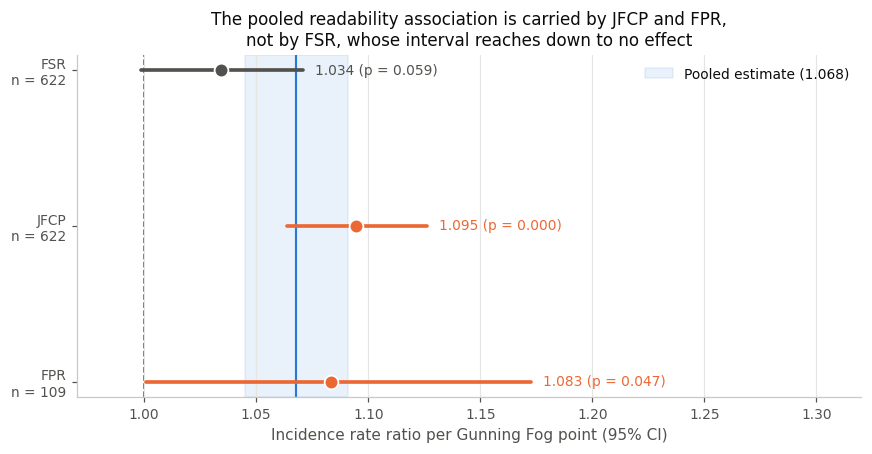

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.2))

y = np.arange(len(strat))[::-1]
ax.axvline(1.0, color=GREY, lw=1, ls="--", zorder=1)
ax.axvspan(pooled_lo, pooled_hi, color=BLUE, alpha=0.10, zorder=0,
           label=f"Pooled estimate ({pooled_irr:.3f})")
ax.axvline(pooled_irr, color=BLUE, lw=1.4, zorder=2)

for yi, (_, r) in zip(y, strat.iterrows()):
    ci_low, ci_high = r["CI low"], r["CI high"]
    colour = GREY if ci_low <= 1.0 <= ci_high else ORANGE
    ax.plot([ci_low, ci_high], [yi, yi], color=colour, lw=2.4, solid_capstyle="round", zorder=3)
    ax.plot(r["IRR"], yi, "o", color=colour, ms=9, zorder=4, markeredgecolor="white", markeredgewidth=1.2)
    ax.annotate(f"{r['IRR']:.3f} (p = {r['p']:.3f})", (ci_high, yi), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=colour)

ax.set_yticks(y)
ax.set_yticklabels([f"{j}\nn = {n:,}" for j, n in zip(strat["journal"], strat["n"])])
ax.set_xlabel("Incidence rate ratio per Gunning Fog point (95% CI)")
ax.set_title("The pooled readability association is carried by JFCP and FPR,\n"
             "not by FSR, whose interval reaches down to no effect")
ax.set_xlim(0.97, 1.32)
ax.legend(loc="upper right", frameon=False, fontsize=9)
ax.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "qc_journal_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


# Part 4: Does the FSR estimate survive the robustness checks?

FSR's estimate is already marginal at $p$ = .059. Two further controls test whether what is left of
it is real. Each is a variable that could produce an apparent readability effect on its own.

## 4.1 All three measures, controlling for abstract length

If the FSR association is genuine it should appear under all three readability indices, as it does
in the pooled model. Each cell below is a separate model within one journal.

In [14]:
rows = []
for j in ORDER:
    g = d[d["journal"] == j]
    row = {"journal": j, "n": len(g)}
    for term in ["fog", "fre", "fkg"]:
        res = fit_nb(g, [term, "log_age", "n_authors", "abstract_words"])
        irr, _, _, p = irr_row(res, term)
        row[f"{MEASURE[term]} IRR"] = irr
        row[f"{MEASURE[term]} p"] = p
    rows.append(row)

pd.DataFrame(rows).round(3)


,journal,n,Gunning Fog IRR,Gunning Fog p,Flesch Reading Ease IRR,Flesch Reading Ease p,Flesch-Kincaid IRR,Flesch-Kincaid p
0,FSR,622,1.032,0.076,0.983,0.000,1.028,0.193
1,JFCP,622,1.095,0.000,0.983,0.000,1.087,0.000
2,FPR,109,1.059,0.156,0.994,0.570,1.029,0.570


FSR fails the checks that JFCP passes. Once abstract length is controlled within FSR, the Fog
association is no longer significant (IRR = 1.032, $p$ = .076) and Flesch-Kincaid gives nothing at
all (IRR = 1.028, $p$ = .193), even though Flesch Reading Ease stays significant. Recall from 1.5
that Fog and Flesch-Kincaid agree on only 79% of the hardest decile and Flesch Reading Ease on 68%,
so this is the three measures disagreeing about FSR specifically, not a rounding artefact.

In JFCP all three measures are significant and agree. In FPR none of the three reaches
significance once length is controlled.

## 4.2 Controlling for research topic

Technical subfields may be both harder to read and differently cited. Without a topic control, a
topic effect could be mistaken for a readability effect. Rather than fit a new topic model, the
eleven-topic NMF partition selected under Question B is reused here, the same partition Questions A
and D use, so that all four questions work from one set of topic definitions.

The code below reproduces that partition from the Question B pipeline: the same text field, the
same stopword list, the same TF-IDF settings and the same NMF configuration and random seed.
Topics enter the model as dummy variables for the dominant topic assignment, with Retirement
Planning as the reference category.

In [15]:
from nltk.stem import WordNetLemmatizer
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

CUSTOM_STOPWORDS = {
    "study", "results", "paper", "research", "article",
    "using", "based", "data", "analysis", "findings",
    "significant", "significantly",
    "academy", "service", "services",
    "right", "rights", "reserved",
}
STOP_WORDS = set(ENGLISH_STOP_WORDS).union(CUSTOM_STOPWORDS)
TOPIC_LABELS = {
    0: "Retirement Planning", 1: "Mutual Funds", 2: "Financial Literacy",
    3: "Risk Tolerance", 4: "Credit and Debt", 5: "Portfolio Investment",
    6: "Household Finance", 7: "Financial Advice", 8: "Student Finance",
    9: "Financial Behaviour", 10: "Tax and Retirement Accounts",
}
FINAL_NMF_K = 11
lemmatiser = WordNetLemmatizer()

def clean_text(text):
    text = re.sub(r"[^a-z\s]", " ", str(text).lower())
    return " ".join(lemmatiser.lemmatize(tok) for tok in text.split() if tok not in STOP_WORDS)

combined = (
    master["title"].fillna("") + " "
    + master["abstract"].fillna("") + " "
    + master["author_keywords"].fillna("").str.replace(";", " ")
)
tfidf = TfidfVectorizer(max_df=0.85, min_df=5, ngram_range=(1, 3))
tfidf_matrix = tfidf.fit_transform(combined.apply(clean_text))

weights = NMF(
    n_components=FINAL_NMF_K, random_state=42, init="nndsvda", max_iter=500
).fit_transform(tfidf_matrix)

master["nmf_topic"] = weights.argmax(axis=1)
master["topic_label"] = master["nmf_topic"].map(TOPIC_LABELS)

d["nmf_topic"] = master.loc[d.index, "nmf_topic"]
d["topic_label"] = master.loc[d.index, "topic_label"]

topic_dummies = pd.get_dummies(d["nmf_topic"], prefix="topic", drop_first=True).astype(float)
d = pd.concat([d, topic_dummies], axis=1)
TOPIC_COLS = list(topic_dummies.columns)

d["topic_label"].value_counts()


topic_label
Financial Behaviour            260
Household Finance              198
Portfolio Investment           195
Financial Advice               151
Student Finance                 95
Financial Literacy              88
Retirement Planning             88
Mutual Funds                    81
Tax and Retirement Accounts     80
Risk Tolerance                  73
Credit and Debt                 44
Name: count, dtype: int64

In [16]:
rows = []
res = fit_nb(d, BASE + ["abstract_words"] + TOPIC_COLS)
irr, lo, hi, p = irr_row(res, "fog")
rows.append({"sample": "Pooled", "n": len(d), "IRR": irr, "CI low": lo, "CI high": hi, "p": p})

for j in ORDER:
    g = d[d["journal"] == j]
    present = [c for c in TOPIC_COLS if g[c].sum() > 0]
    res = fit_nb(g, ["fog", "log_age", "n_authors", "abstract_words"] + present)
    irr, lo, hi, p = irr_row(res, "fog")
    rows.append({"sample": j, "n": len(g), "IRR": irr, "CI low": lo, "CI high": hi, "p": p})

pd.DataFrame(rows).round(3)


,sample,n,IRR,CI low,CI high,p
0,Pooled,1353,1.045,1.024,1.067,0.000
1,FSR,622,1.015,0.982,1.049,0.371
2,JFCP,622,1.062,1.033,1.092,0.000
3,FPR,109,1.057,0.973,1.149,0.187


Adding research topic removes the FSR association altogether. The Fog estimate in FSR falls to
1.015 (95% CI 0.982 to 1.049, $p$ = .371), which is no association at all. JFCP keeps a clear one
at 1.062 ($p < .001$), and FPR becomes non-significant at 1.057 ($p$ = .187).

In the pooled model the topic control shrinks the estimate from 1.068 to 1.045 but leaves it
significant, which again reflects how much of the pooled sample JFCP contributes.

The pattern across 4.1 and 4.2 is consistent. What looked like a readability effect in FSR was
partly abstract length and partly research topic. Neither JFCP's association nor the pooled one is
explained away this way, so the difference between FSR and JFCP is not a matter of statistical
power alone.

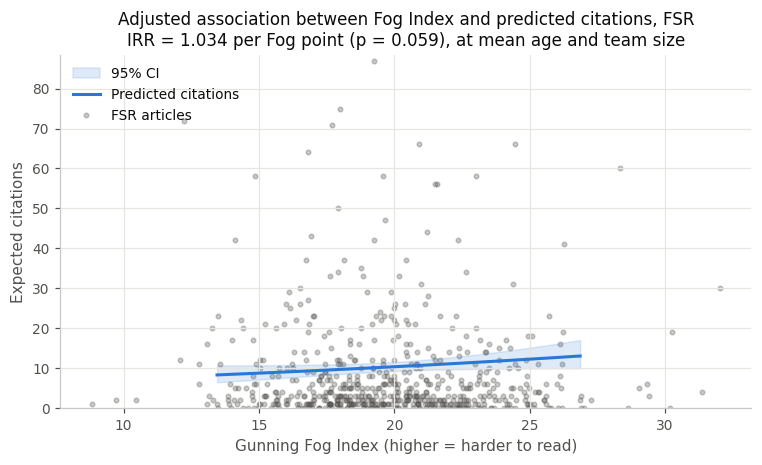

In [17]:
fsr = d[d["journal"] == "FSR"]
m_fsr = fit_nb(fsr, ["fog", "log_age", "n_authors"])

grid = pd.DataFrame({
    "fog": np.linspace(fsr["fog"].quantile(0.02), fsr["fog"].quantile(0.98), 120),
    "log_age": fsr["log_age"].mean(),
    "n_authors": fsr["n_authors"].mean(),
})

Xg = sm.add_constant(grid[["fog", "log_age", "n_authors"]], has_constant="add")
beta = m_fsr.params.drop("alpha")
cov = m_fsr.cov_params().drop(index="alpha", columns="alpha")

eta = Xg.values @ beta.values
se = np.sqrt((Xg.values @ cov.values * Xg.values).sum(axis=1))

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.fill_between(grid["fog"], np.exp(eta - 1.96 * se), np.exp(eta + 1.96 * se),
                color=BLUE, alpha=0.15, label="95% CI")
ax.plot(grid["fog"], np.exp(eta), color=BLUE, label="Predicted citations")
ax.plot(fsr["fog"], fsr["cited_by"], "o", color=GREY, ms=3, alpha=0.30,
        label="FSR articles", zorder=0)

ax.set_ylim(0, np.percentile(fsr["cited_by"], 97))
ax.set_xlabel("Gunning Fog Index (higher = harder to read)")
ax.set_ylabel("Expected citations")
ax.set_title("Adjusted association between Fog Index and predicted citations, FSR\n"
             f"IRR = {np.exp(m_fsr.params['fog']):.3f} per Fog point "
             f"(p = {m_fsr.pvalues['fog']:.3f}), at mean age and team size")
ax.legend(frameon=False, fontsize=9, loc="upper left")

fig.tight_layout()
fig.savefig(FIG_DIR / "qc_fog_predicted.png", dpi=200, bbox_inches="tight")
plt.show()


# Conclusion

**Readability is associated with citations across these three journals, but not within FSR.**
Pooled across all three, each additional Gunning Fog point is associated with 6.8% more citations
(IRR = 1.068, $p < .001$), so harder abstracts are cited more. That result is stable under all
three readability indices and under an abstract length control, and it sides with Sienkiewicz and
Altmann (2016) rather than Gazni (2011).

**The pooled finding is mostly JFCP.** Fitted separately, the association is 9.5% per Fog point in
JFCP and 8.3% in FPR, but 3.4% in FSR with a confidence interval that includes zero ($p$ = .059).
The difference is larger than sampling noise: a Fog-by-journal interaction improves fit
(LR $\chi^2(2)$ = 8.19, $p$ = .017), and JFCP's slope is significantly steeper than FSR's
($p$ = .004). A single pooled slope does not describe these three journals, and the one it fits
worst is the journal AFS edits.

**What survives in FSR does not survive the controls.** Within FSR, adding abstract length leaves
Fog non-significant ($p$ = .076) and Flesch-Kincaid null ($p$ = .193). Adding research topic
removes the association entirely (IRR = 1.015, $p$ = .371). JFCP's association survives both. So
the FSR estimate is not a weaker version of JFCP's finding, it is attributable to length and topic.

**Age had to be controlled for the question to be answerable at all.** Unadjusted, Fog score and
citations look unrelated in FSR ($\rho$ = $-0.05$, $p$ = .27). Fog scores fall with paper age in
every journal while citations rise with it, so age suppresses the association towards zero. The
unadjusted nulls and the adjusted estimates disagree for this reason, and reporting only the raw
correlation would have given the wrong answer twice over.

### What this means for AFS

There is no evidence here that asking FSR authors to simplify their abstracts would raise citations,
and no evidence that asking them to complicate them would either. Within FSR the adjusted estimate
is 1.5% per Fog point with a $p$-value of .37, and the effect such a request could plausibly
achieve is smaller than the measurement disagreement between the three indices. Editorial effort
spent on abstract wording is better spent elsewhere, and Question B's topic findings are the larger
lever.

The result that does hold is about the comparison rather than about FSR. JFCP's abstracts are
harder than FSR's on all three measures and its citation advantage per Fog point survives both
the length and the topic control. This analysis cannot say why, and the explanation most consistent with the topic control is
that readability is standing in for something else that differs between the two journals, most
likely the kind of work each publishes rather than how that work is written up.

### Limitations

The design is observational and nothing here is causal. Abstract readability is not randomly
assigned, and the topic control in 4.2 demonstrates the problem directly: a variable correlated
with both readability and citations absorbed the entire FSR association. Other such variables
almost certainly remain unmeasured.

Readability formulas were built for continuous prose and are only approximate on academic
abstracts, where notation, acronyms and long technical compounds inflate syllable counts without
making the text harder for its intended reader. This affects all three journals, so it is unlikely
to drive the between-journal differences, but it does mean the absolute Fog levels in 1.4 should
not be read as literal reading grades.

FPR contributes 109 articles. Its interval is wide enough to be consistent with either FSR's
estimate or JFCP's, and the FPR results above should be treated as indicative rather than
informative.

### References

Didegah, F., & Thelwall, M. (2013). Which factors help authors produce the highest impact
research? Collaboration, journal and document properties. *Journal of Informetrics*, 7(4),
861-873.

Gazni, A. (2011). Are the abstracts of high impact articles more readable? Investigating the
evidence from top research institutions in the world. *Journal of Information Science*, 37(3),
273-281.

Kousha, K., & Thelwall, M. (2024). Factors associating with or predicting more cited or higher
quality journal articles. *Journal of the Association for Information Science and Technology*,
75(3), 215-244.

Sienkiewicz, J., & Altmann, E. G. (2016). Impact of lexical and sentiment factors on the
popularity of scientific papers. *Royal Society Open Science*, 3(6).